# Laboratorio 10 - Task 4: ¿Merece confianza el mapa de Grad-CAM?

**Semilla:** 42
**Modelo:** ResNet-18 con pesos de ImageNet (`IMAGENET1K_V1`), el mismo del Task 1.

En este notebook ponemos a prueba los mapas de Grad-CAM del Task 1.2 con dos validaciones: las métricas de deletion e insertion, comparadas contra órdenes aleatorios de píxeles, y la prueba de aleatorización de parámetros en cascada. Como en el Task 1, no usamos `pytorch-grad-cam`, `captum` ni librerías similares.

## Preparación: modelo, imágenes y Grad-CAM del Task 1

Repetimos el preprocesamiento del Task 1.1 y la misma clase `GradCAM` del Task 1.2 (hooks sobre `layer4`, retropropagación desde el logit). Calculamos el mapa de la clase de mayor probabilidad de cada imagen y comprobamos que las clases sean las del Task 1: German shepherd (235) en (a) y (b), y banana (954) en (c).

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.stats import spearmanr
import torch
import torch.nn.functional as F
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import functional as TF

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
IMAGE_DIR = PROJECT_ROOT / 'data' / 'images'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'task4'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=WEIGHTS).to(DEVICE).eval()
CLASS_NAMES = WEIGHTS.meta['categories']
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
GRAY = 0.5  # gris medio en RGB, el mismo del Task 1.4c

def preprocess_image(path):
    image = Image.open(path).convert('RGB')
    image_224 = TF.center_crop(TF.resize(image, 256), [224, 224])
    return image_224, TF.to_tensor(image_224)

def normalize(rgb_batch):
    '''Lleva imágenes RGB en [0, 1] (N, 3, 224, 224) a la entrada normalizada del modelo.'''
    return ((rgb_batch - MEAN) / STD).to(DEVICE)

def minmax(x, eps=1e-12):
    return (x - x.min()) / (x.max() - x.min()).clamp_min(eps)

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.handles = [
            target_layer.register_forward_hook(self._save_activations),
            target_layer.register_full_backward_hook(self._save_gradients),
        ]

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, input_tensor, class_index=None):
        self.model.zero_grad(set_to_none=True)
        logits = self.model(input_tensor)
        if class_index is None:
            class_index = int(logits.argmax(dim=1).item())
        logits[0, class_index].backward()
        alpha = self.gradients.mean(dim=(2, 3), keepdim=True)
        raw_7 = (alpha * self.activations).sum(dim=1)[0]
        normalized_7 = minmax(F.relu(raw_7))
        normalized_224 = F.interpolate(
            normalized_7[None, None], size=(224, 224), mode='bilinear', align_corners=False
        )[0, 0]
        return {'class_index': class_index, 'logits': logits.detach(), 'raw_7': raw_7,
                'normalized_7': normalized_7, 'normalized_224': normalized_224}

    def close(self):
        for handle in self.handles:
            handle.remove()

IMAGES = {
    'a': IMAGE_DIR / 'a_objeto_claro.jpg',
    'b': IMAGE_DIR / 'b_dos_objetos.jpg',
    'c': IMAGE_DIR / 'c_contexto_enganoso.jpg',
}
gradcam = GradCAM(model, model.layer4)
loaded = {}
for key, path in IMAGES.items():
    image_224, rgb = preprocess_image(path)
    result = gradcam(normalize(rgb[None]))
    probability = result['logits'].softmax(1)[0, result['class_index']].item()
    loaded[key] = {'image': image_224, 'rgb': rgb, 'class_index': result['class_index'],
                   'probability': probability, 'map_7': result['normalized_7'].cpu(),
                   'raw_7': result['raw_7'].cpu(), 'map_224': result['normalized_224'].cpu()}
gradcam.close()

assert [loaded[k]['class_index'] for k in 'abc'] == [235, 235, 954]
display(pd.DataFrame([
    {'imagen': k, 'clase': CLASS_NAMES[v['class_index']], 'indice': v['class_index'], 'probabilidad': v['probability']}
    for k, v in loaded.items()
]).style.format({'probabilidad': '{:.6f}'}).hide(axis='index'))

imagen,clase,indice,probabilidad
a,German shepherd,235,0.976751
b,German shepherd,235,0.401887
c,banana,954,0.755744


## Task 4.1: Deletion e insertion

Para cada imagen ordenamos los $224\times224=50\,176$ píxeles por el valor del mapa de Grad-CAM, de mayor a menor, y en $P=20$ pasos modificamos la fracción $k/P$ de los píxeles más importantes:

- **Deletion:** reemplazamos esos píxeles por gris medio (0.5 en cada canal RGB, antes de normalizar) y registramos la probabilidad $c_k$ de la clase. $\text{AUC}_{del}=\frac{1}{P}\sum_{k=1}^{P}c_k$. **Más bajo es mejor**: si el mapa señala lo importante, la probabilidad debería caer rápido.
- **Insertion:** partimos de la imagen desenfocada con un filtro gaussiano de $\sigma=10$ píxeles (núcleo de $61\times61$) e insertamos los píxeles originales más importantes. $\text{AUC}_{ins}$ se calcula igual. **Más alto es mejor**: la probabilidad debería recuperarse rápido.

Repetimos ambas pruebas con 10 órdenes aleatorios de píxeles (semilla 42) como referencia de azar. La clase evaluada es siempre la de mayor probabilidad en la imagen original. Para no depender del orden entre píxeles con el mismo valor usamos un ordenamiento estable.

In [2]:
P = 20
N_RANDOM = 10
BLUR_SIGMA = 10
BLUR_KERNEL = 2 * int(np.ceil(3 * BLUR_SIGMA)) + 1  # 61
N_PIXELS = 224 * 224

@torch.no_grad()
def class_probability(rgb_batch, class_index, batch_size=21):
    probs = []
    for start in range(0, len(rgb_batch), batch_size):
        logits = model(normalize(rgb_batch[start:start + batch_size]))
        probs.append(logits.softmax(1)[:, class_index].cpu())
    return torch.cat(probs).numpy()

def perturbation_curve(source, target, order, class_index):
    '''Devuelve c_0..c_P: en el paso k, los primeros k/P píxeles de `order` toman su valor de `target`.'''
    frames = []
    for k in range(P + 1):
        mask = torch.zeros(N_PIXELS, dtype=torch.bool)
        mask[order[: round(k * N_PIXELS / P)]] = True
        mask = mask.view(1, 224, 224)
        frames.append(torch.where(mask, target, source))
    return class_probability(torch.stack(frames), class_index)

rng_orders = np.random.default_rng(SEED)
curves = {}
rows_41 = []
for key, item in loaded.items():
    rgb = item['rgb']
    gray = torch.full_like(rgb, GRAY)
    blurred = TF.gaussian_blur(rgb, kernel_size=[BLUR_KERNEL, BLUR_KERNEL], sigma=[BLUR_SIGMA, BLUR_SIGMA])
    map_order = torch.from_numpy(np.argsort(-item['map_224'].numpy().ravel(), kind='stable').copy())
    random_orders = [torch.from_numpy(rng_orders.permutation(N_PIXELS)) for _ in range(N_RANDOM)]

    cls = item['class_index']
    deletion_map = perturbation_curve(rgb, gray, map_order, cls)
    insertion_map = perturbation_curve(blurred, rgb, map_order, cls)
    deletion_rand = np.array([perturbation_curve(rgb, gray, o, cls) for o in random_orders])
    insertion_rand = np.array([perturbation_curve(blurred, rgb, o, cls) for o in random_orders])
    curves[key] = {'del_map': deletion_map, 'ins_map': insertion_map,
                   'del_rand': deletion_rand, 'ins_rand': insertion_rand, 'blurred': blurred}

    auc = lambda curve: float(np.mean(curve[..., 1:], axis=-1).mean()) if curve.ndim == 1 else np.mean(curve[:, 1:], axis=1)
    auc_del_map, auc_ins_map = auc(deletion_map), auc(insertion_map)
    auc_del_rand, auc_ins_rand = auc(deletion_rand), auc(insertion_rand)
    for metric, value, rand in [('deletion', auc_del_map, auc_del_rand), ('insertion', auc_ins_map, auc_ins_rand)]:
        better = (rand.mean() - value) if metric == 'deletion' else (value - rand.mean())
        rows_41.append({
            'imagen': key, 'clase': CLASS_NAMES[cls], 'metrica': metric,
            'AUC_GradCAM': value, 'AUC_azar_media': rand.mean(), 'AUC_azar_std': rand.std(ddof=1),
            'diferencia_a_favor_GradCAM': better, 'desviaciones_std': better / rand.std(ddof=1),
            'c0': curves[key]['del_map' if metric == 'deletion' else 'ins_map'][0],
        })

metrics_41 = pd.DataFrame(rows_41)
metrics_41.to_csv(RESULTS_DIR / 'task4_1_deletion_insertion.csv', index=False)
for key in loaded:
    print(f'Imagen ({key}) - {CLASS_NAMES[loaded[key]["class_index"]]}')
    display(metrics_41[metrics_41['imagen'] == key].drop(columns=['imagen', 'clase'])
            .style.format(precision=4).hide(axis='index'))

Imagen (a) - German shepherd


metrica,AUC_GradCAM,AUC_azar_media,AUC_azar_std,diferencia_a_favor_GradCAM,desviaciones_std,c0
deletion,0.1648,0.3372,0.0247,0.1724,6.9829,0.9768
insertion,0.7955,0.3164,0.0291,0.4791,16.4450,0.0034


Imagen (b) - German shepherd


metrica,AUC_GradCAM,AUC_azar_media,AUC_azar_std,diferencia_a_favor_GradCAM,desviaciones_std,c0
deletion,0.0093,0.0084,0.0029,-0.0009,-0.3155,0.4019
insertion,0.6479,0.0436,0.0081,0.6043,74.3247,0.0028


Imagen (c) - banana


metrica,AUC_GradCAM,AUC_azar_media,AUC_azar_std,diferencia_a_favor_GradCAM,desviaciones_std,c0
deletion,0.0092,0.0580,0.0102,0.0487,4.7687,0.7557
insertion,0.7831,0.1794,0.0227,0.6037,26.5681,0.0339


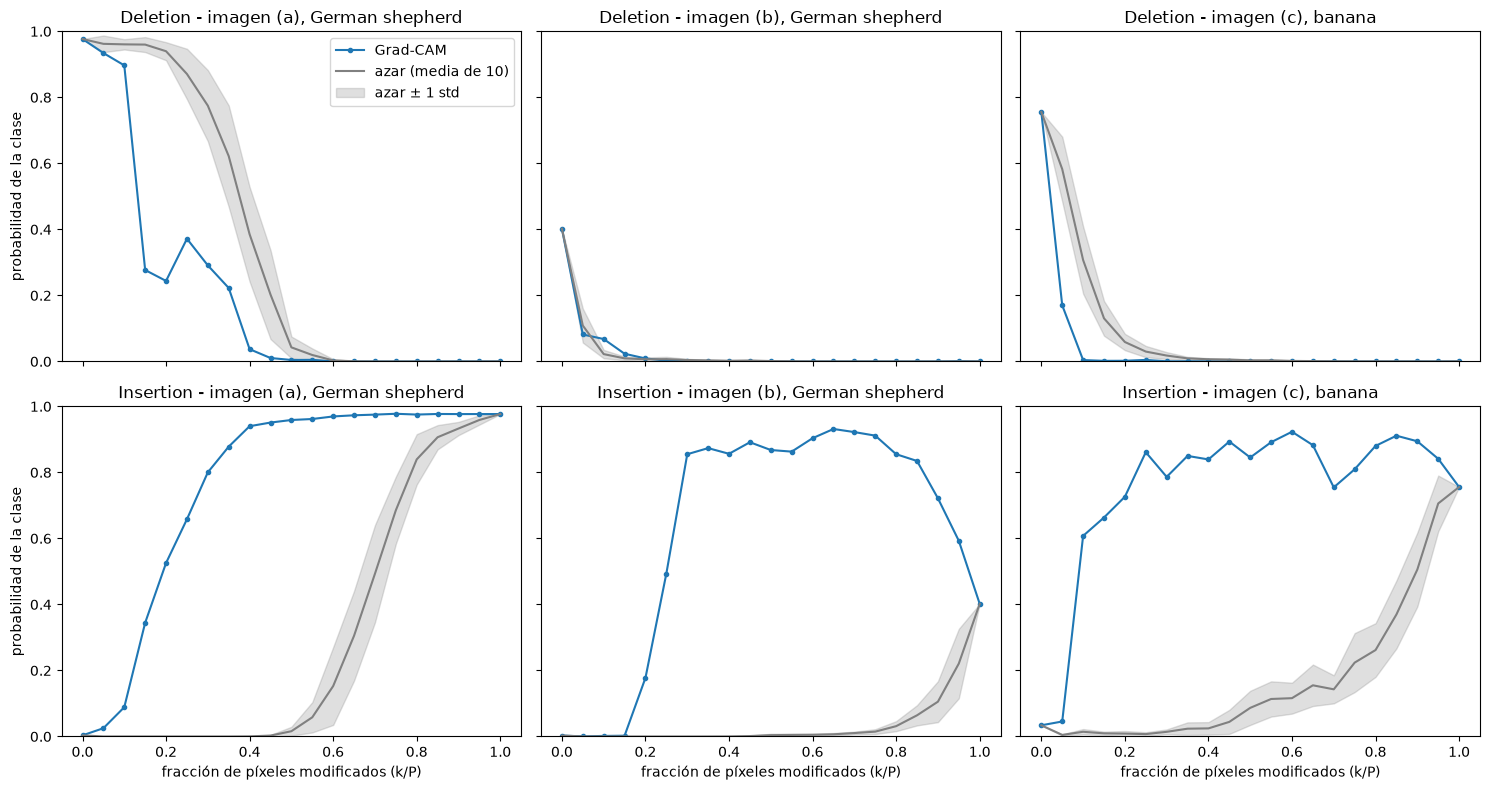

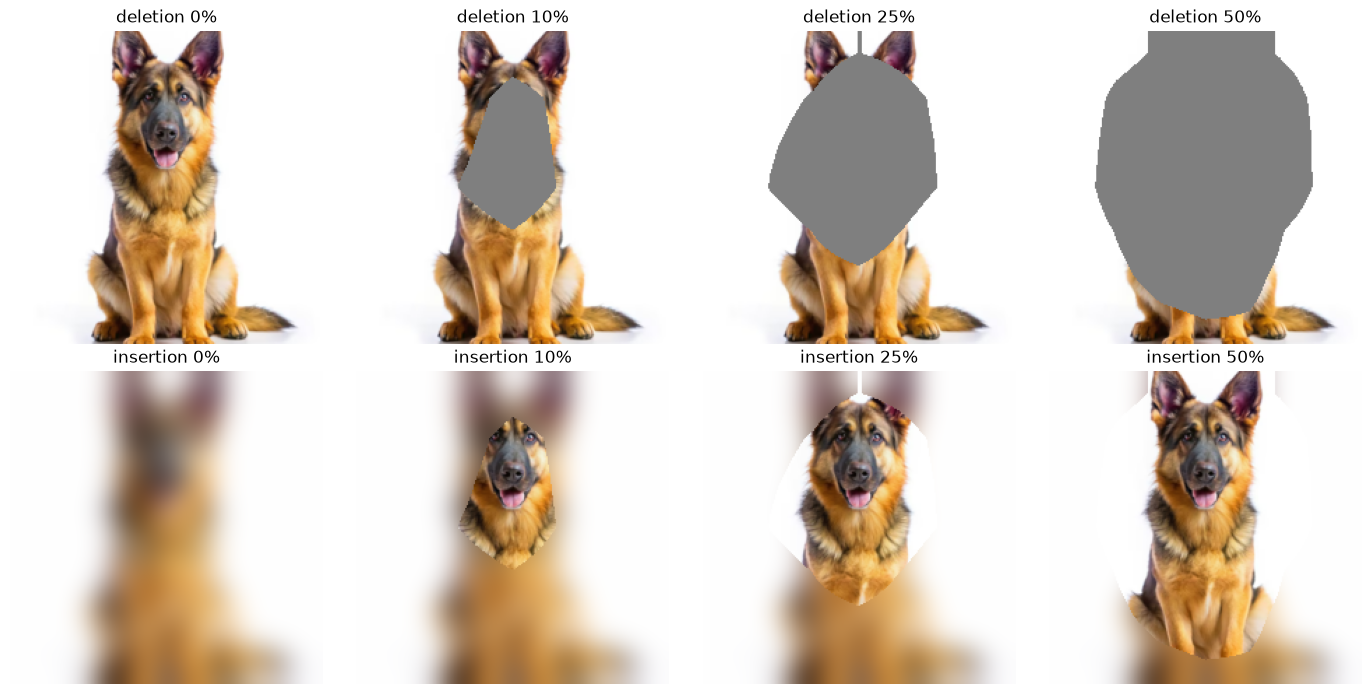

In [3]:
fractions = np.arange(P + 1) / P
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for col, key in enumerate(loaded):
    for row, (kind, title) in enumerate([('del', 'Deletion'), ('ins', 'Insertion')]):
        ax = axes[row, col]
        rand = curves[key][f'{kind}_rand']
        ax.plot(fractions, curves[key][f'{kind}_map'], marker='o', markersize=3, label='Grad-CAM')
        ax.plot(fractions, rand.mean(0), color='gray', label='azar (media de 10)')
        ax.fill_between(fractions, rand.mean(0) - rand.std(0, ddof=1), rand.mean(0) + rand.std(0, ddof=1),
                        color='gray', alpha=0.25, label='azar ± 1 std')
        ax.set_title(f'{title} - imagen ({key}), {CLASS_NAMES[loaded[key]["class_index"]]}')
        ax.set_ylim(0, 1)
        if row == 1:
            ax.set_xlabel('fracción de píxeles modificados (k/P)')
        if col == 0:
            ax.set_ylabel('probabilidad de la clase')
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task4_1_curves.png', dpi=180, bbox_inches='tight')
plt.show()

# Cómo se ven los pasos: imagen (a), deletion e insertion al 10%, 25% y 50%.
key = 'a'
order = torch.from_numpy(np.argsort(-loaded[key]['map_224'].numpy().ravel(), kind='stable').copy())
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for col, frac in enumerate([0.0, 0.10, 0.25, 0.50]):
    mask = torch.zeros(N_PIXELS, dtype=torch.bool)
    mask[order[: round(frac * N_PIXELS)]] = True
    mask = mask.view(1, 224, 224)
    rgb = loaded[key]['rgb']
    deleted = torch.where(mask, torch.full_like(rgb, GRAY), rgb)
    inserted = torch.where(mask, rgb, curves[key]['blurred'])
    axes[0, col].imshow(deleted.permute(1, 2, 0))
    axes[0, col].set_title(f'deletion {frac:.0%}')
    axes[1, col].imshow(inserted.permute(1, 2, 0))
    axes[1, col].set_title(f'insertion {frac:.0%}')
for ax in axes.ravel():
    ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task4_1_steps_a.png', dpi=150, bbox_inches='tight')
plt.show()

### Respuesta 4.1

En deletion un AUC **menor** es mejor y en insertion uno **mayor**. La columna "a favor de Grad-CAM" es la diferencia con la media del azar en la dirección favorable, y la siguiente la expresa en desviaciones estándar de los 10 órdenes aleatorios.

**Imagen (a), German shepherd ($c_0=0.9768$)**

| Métrica | AUC Grad-CAM | Azar (media ± std) | A favor de Grad-CAM | Desviaciones std |
|---|---:|---:|---:|---:|
| Deletion | 0.1648 | 0.3372 ± 0.0247 | 0.1724 | 6.98 |
| Insertion | 0.7955 | 0.3164 ± 0.0291 | 0.4791 | 16.44 |

**Imagen (b), German shepherd ($c_0=0.4019$)**

| Métrica | AUC Grad-CAM | Azar (media ± std) | A favor de Grad-CAM | Desviaciones std |
|---|---:|---:|---:|---:|
| Deletion | 0.0093 | 0.0084 ± 0.0029 | −0.0009 | −0.32 |
| Insertion | 0.6479 | 0.0436 ± 0.0081 | 0.6043 | 74.32 |

**Imagen (c), banana ($c_0=0.7557$)**

| Métrica | AUC Grad-CAM | Azar (media ± std) | A favor de Grad-CAM | Desviaciones std |
|---|---:|---:|---:|---:|
| Deletion | 0.0092 | 0.0580 ± 0.0102 | 0.0487 | 4.77 |
| Insertion | 0.7831 | 0.1794 ± 0.0227 | 0.6037 | 26.57 |

En cinco de las seis pruebas el mapa supera claramente al azar. La excepción es deletion en la imagen (b): ahí el mapa queda prácticamente empatado con el orden aleatorio, porque la probabilidad de partida ya es baja (0.40) y cae casi a cero con cualquier orden en el primer paso (0.082 con el mapa y 0.109 en promedio con el azar al eliminar el 5% de los píxeles). Interpretamos la forma de las curvas y el efecto del gris en el Task 4.3a.

## Task 4.2: Aleatorización de parámetros en cascada

Partimos de una copia del modelo original y reinicializamos sus pesos con la inicialización aleatoria por defecto de PyTorch (`reset_parameters()`), de forma acumulada y desde la salida hacia la entrada: primero `fc`; luego, además, `layer4`, `layer3`, `layer2`, `layer1` y finalmente `conv1` (con su `bn1`). En cada bloque reiniciamos todos los módulos que tienen `reset_parameters`: las convoluciones, la capa lineal y las normalizaciones por lotes, cuyas estadísticas acumuladas vuelven a media 0 y varianza 1.

En cada etapa calculamos el mapa de Grad-CAM de $7\times7$ para la clase que era la de mayor probabilidad en el modelo **original** (no la nueva predicción) y su correlación de Spearman con el mapa original. Usamos el mapa normalizado (después de ReLU y min-max) y, como complemento, el mapa antes de ReLU, porque si la ReLU anula todo el mapa queda constante y su correlación no está definida. Una semilla fija hace reproducible la reinicialización.

In [4]:
STAGES = ['fc', 'layer4', 'layer3', 'layer2', 'layer1', 'conv1']

def reset_block(net, name):
    blocks = [net.conv1, net.bn1] if name == 'conv1' else [getattr(net, name)]
    count = 0
    for block in blocks:
        for module in block.modules():
            if hasattr(module, 'reset_parameters'):
                module.reset_parameters()
                count += 1
    return count

def spearman_or_nan(a, b):
    a, b = np.asarray(a).ravel(), np.asarray(b).ravel()
    if np.allclose(a, a[0]) or np.allclose(b, b[0]):
        return np.nan
    return spearmanr(a, b).statistic

torch.manual_seed(SEED)
cascade = copy.deepcopy(model).eval()
cascade_cam = GradCAM(cascade, cascade.layer4)
cascade_rows, cascade_maps = [], {key: [] for key in loaded}
for stage_number, stage in enumerate(STAGES, start=1):
    n_modules = reset_block(cascade, stage)
    for key, item in loaded.items():
        result = cascade_cam(normalize(item['rgb'][None]), item['class_index'])
        new_map = result['normalized_7'].cpu()
        cascade_maps[key].append(new_map)
        logits = result['logits'][0]
        cascade_rows.append({
            'etapa': stage_number,
            'aleatorizado_hasta': stage,
            'modulos_reiniciados': n_modules,
            'imagen': key,
            'spearman_mapa': spearman_or_nan(item['map_7'], new_map),
            'spearman_sin_relu': spearman_or_nan(item['raw_7'], result['raw_7'].cpu()),
            'mapa_constante': bool(np.allclose(new_map, new_map.flatten()[0])),
            'prob_clase_original': logits.softmax(0)[item['class_index']].item(),
            'nueva_prediccion': CLASS_NAMES[int(logits.argmax())],
        })
cascade_cam.close()

cascade_df = pd.DataFrame(cascade_rows)
cascade_df.to_csv(RESULTS_DIR / 'task4_2_cascade.csv', index=False)
cascade_table = cascade_df.pivot(index='aleatorizado_hasta', columns='imagen', values='spearman_mapa').loc[STAGES]
cascade_table_raw = cascade_df.pivot(index='aleatorizado_hasta', columns='imagen', values='spearman_sin_relu').loc[STAGES]
print('Spearman entre el mapa de 7x7 de cada etapa y el original (mapa normalizado)')
display(cascade_table.style.format('{:.4f}', na_rep='constante'))
print('Spearman antes de ReLU (complemento)')
display(cascade_table_raw.style.format('{:.4f}', na_rep='constante'))
display(cascade_df.drop(columns=['spearman_mapa', 'spearman_sin_relu']).style.format({'prob_clase_original': '{:.2e}'}).hide(axis='index'))

Spearman entre el mapa de 7x7 de cada etapa y el original (mapa normalizado)


imagen,a,b,c
aleatorizado_hasta,,,
fc,0.6939,0.0173,0.3641
layer4,0.2605,0.1509,-0.2606
layer3,0.4801,0.3177,0.1647
layer2,-0.1220,0.3265,0.0269
layer1,-0.0001,0.0615,0.2690
conv1,-0.6139,-0.1933,0.4253


Spearman antes de ReLU (complemento)


imagen,a,b,c
aleatorizado_hasta,,,
fc,0.6939,-0.0099,0.3644
layer4,0.2605,0.1143,-0.2693
layer3,0.4801,0.2839,0.1702
layer2,-0.1220,0.2862,0.0327
layer1,-0.0001,0.0354,0.2755
conv1,-0.6139,-0.1562,0.4205


etapa,aleatorizado_hasta,modulos_reiniciados,imagen,mapa_constante,prob_clase_original,nueva_prediccion
1,fc,1,a,False,2.32e-03,hay
1,fc,1,b,False,1.87e-03,fire screen
1,fc,1,c,False,2.11e-03,fountain pen
2,layer4,10,a,False,1.11e-03,barracouta
2,layer4,10,b,False,1.15e-03,hog
2,layer4,10,c,False,1.01e-03,barracouta
3,layer3,10,a,False,1.06e-03,killer whale
3,layer3,10,b,False,1.08e-03,killer whale
3,layer3,10,c,False,1.01e-03,killer whale
4,layer2,10,a,False,1.02e-03,colobus


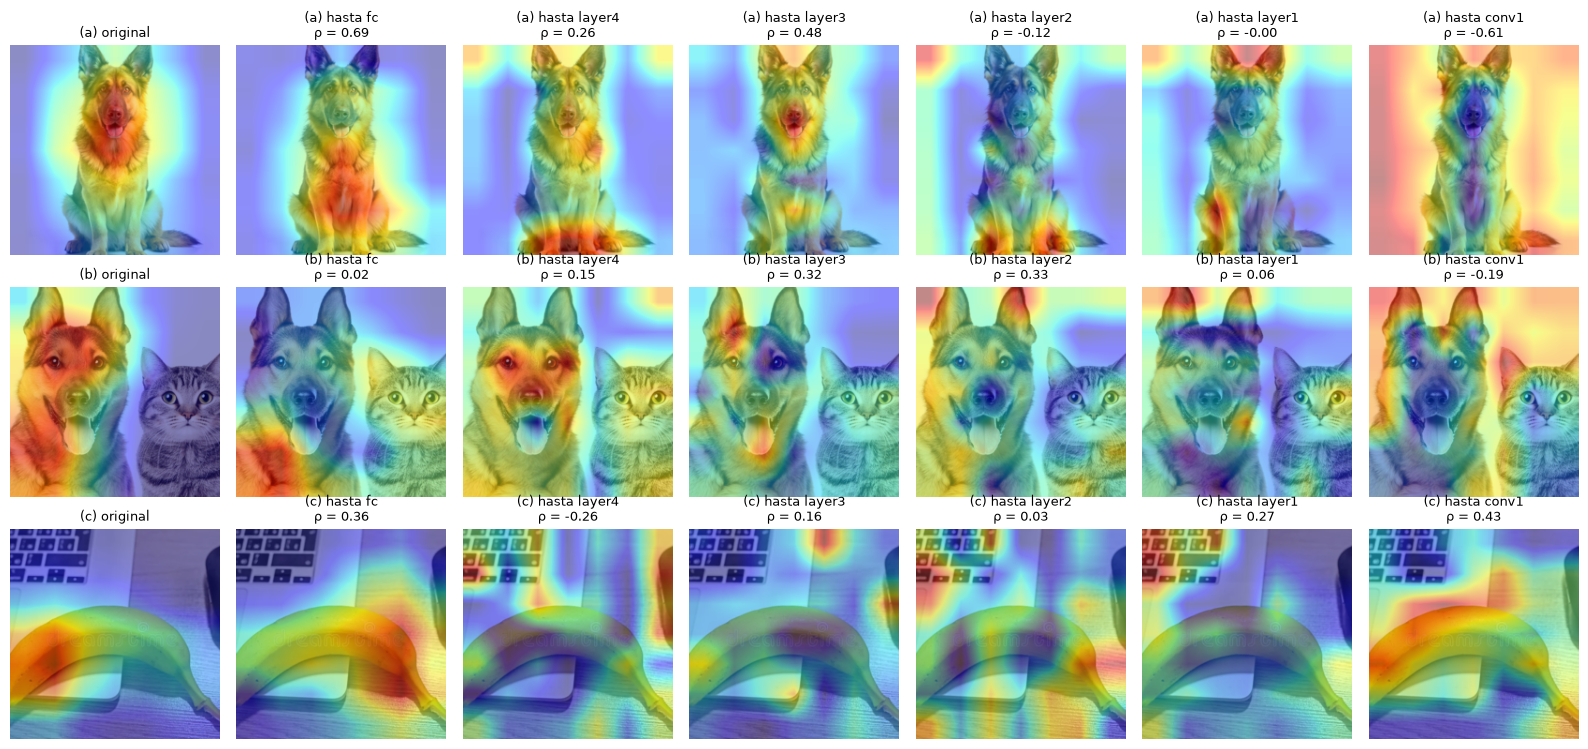

In [5]:
fig, axes = plt.subplots(3, len(STAGES) + 1, figsize=(16, 7.5))
for row, key in enumerate(loaded):
    maps_row = [loaded[key]['map_7']] + cascade_maps[key]
    titles = ['original'] + [f'hasta {s}' for s in STAGES]
    for col, (heat, title) in enumerate(zip(maps_row, titles)):
        ax = axes[row, col]
        ax.imshow(loaded[key]['image'])
        up = F.interpolate(heat[None, None], size=(224, 224), mode='bilinear', align_corners=False)[0, 0]
        ax.imshow(up, cmap='jet', alpha=0.45, vmin=0, vmax=1)
        if col > 0:
            rho = cascade_table.loc[STAGES[col - 1], key]
            title += '\nconstante' if np.isnan(rho) else f'\nρ = {rho:.2f}'
        ax.set_title(f'({key}) {title}', fontsize=9)
        ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task4_2_cascade_maps.png', dpi=150, bbox_inches='tight')
plt.show()

### Respuesta 4.2

Spearman entre el mapa de Grad-CAM de $7\times7$ de cada etapa (para la clase original de cada imagen) y el mapa del modelo original:

| Aleatorizado hasta | (a) German shepherd | (b) German shepherd | (c) banana |
|---|---:|---:|---:|
| `fc` | 0.6939 | 0.0173 | 0.3641 |
| `layer4` | 0.2605 | 0.1509 | −0.2606 |
| `layer3` | 0.4801 | 0.3177 | 0.1647 |
| `layer2` | −0.1220 | 0.3265 | 0.0269 |
| `layer1` | −0.0001 | 0.0615 | 0.2690 |
| `conv1` | −0.6139 | −0.1933 | 0.4253 |

Ningún mapa quedó constante después de la ReLU, así que todas las correlaciones están definidas; las calculadas antes de la ReLU son casi iguales. Desde la primera etapa el modelo deja de reconocer las imágenes: la probabilidad de la clase original cae a entre 0.0019 y 0.0023 (el azar entre 1000 clases es 0.001) y la predicción pasa a ser `hay`, `fire screen` o `fountain pen`. Con todo el modelo aleatorizado, las tres imágenes se clasifican como `colobus`. Las correlaciones no bajan de forma monótona: suben y bajan entre etapas. Lo analizamos en el Task 4.3b.

## Task 4.3: Análisis

### 4.3a: Comparación con el azar, forma de las curvas y efecto de los parches grises

Resumimos la ventaja de Grad-CAM sobre el azar del Task 4.1 y, para revisar el efecto del gris, repetimos deletion usando como referencia la imagen desenfocada ($\sigma=10$) en lugar de gris medio, con el mapa y con 10 órdenes aleatorios nuevos (semilla 42). El enunciado lo pide para la imagen (a); lo hacemos en las tres porque en (b) el gris es justamente el caso dudoso. También contamos cuántas celdas del mapa de $7\times7$ concentran la mayor parte del mapa, para interpretar los escalones de las curvas.

Ventaja de Grad-CAM sobre el azar en el Task 4.1 (desviaciones estándar)


metrica,deletion,insertion
imagen,,
a,6.98,16.44
b,-0.32,74.32
c,4.77,26.57


imagen,celdas_7x7_con_valor_>_0.5,fraccion_de_la_imagen,pixeles_por_celda,celdas_por_paso_de_5%
a,14,0.286,1024,2.450
b,21,0.429,1024,2.450
c,8,0.163,1024,2.450


imagen,referencia,AUC_del_GradCAM,AUC_del_azar_media,AUC_del_azar_std,desviaciones_std,p_azar_5%,p_GradCAM_5%
a,gris,0.1648,0.3372,0.0247,6.9829,0.9621,0.9343
a,desenfocada,0.1339,0.2743,0.0316,4.4461,0.9513,0.9365
b,gris,0.0093,0.0084,0.0029,-0.3155,0.1087,0.0816
b,desenfocada,0.0108,0.0253,0.0045,3.2104,0.2426,0.1223
c,gris,0.0092,0.0580,0.0102,4.7687,0.5826,0.1700
c,desenfocada,0.0340,0.1245,0.0101,8.9370,0.6333,0.2495


Imagen (a): probabilidad en los primeros pasos de deletion con gris (mapa)
[0.977 0.934 0.897 0.277 0.244 0.372 0.291 0.223]


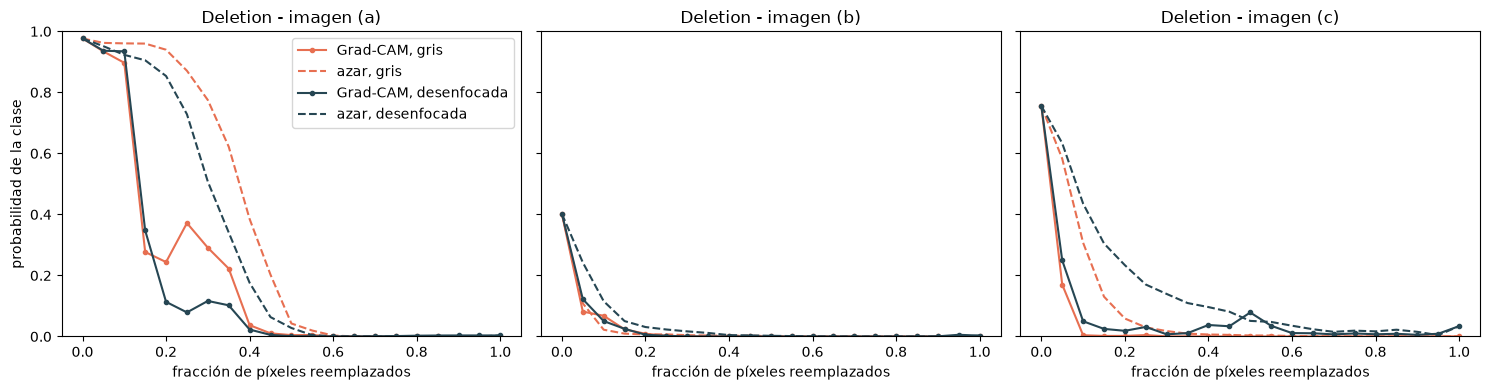

In [6]:
print('Ventaja de Grad-CAM sobre el azar en el Task 4.1 (desviaciones estándar)')
display(metrics_41.pivot(index='imagen', columns='metrica', values='desviaciones_std').style.format('{:.2f}'))

cells_rows = []
for key, item in loaded.items():
    m7 = item['map_7'].numpy().ravel()
    cells_rows.append({'imagen': key, 'celdas_7x7_con_valor_>_0.5': int((m7 > 0.5).sum()),
                       'fraccion_de_la_imagen': (m7 > 0.5).mean(),
                       'pixeles_por_celda': (224 // 7) ** 2, 'celdas_por_paso_de_5%': 0.05 * 49})
display(pd.DataFrame(cells_rows).style.format(precision=3).hide(axis='index'))

rng_blur = np.random.default_rng(SEED)
blur_rows = []
for key, item in loaded.items():
    rgb, blurred, cls = item['rgb'], curves[key]['blurred'], item['class_index']
    map_order = torch.from_numpy(np.argsort(-item['map_224'].numpy().ravel(), kind='stable').copy())
    deletion_blur_map = perturbation_curve(rgb, blurred, map_order, cls)
    deletion_blur_rand = np.array([
        perturbation_curve(rgb, blurred, torch.from_numpy(rng_blur.permutation(N_PIXELS)), cls)
        for _ in range(N_RANDOM)
    ])
    curves[key]['del_blur_map'], curves[key]['del_blur_rand'] = deletion_blur_map, deletion_blur_rand
    for reference, map_curve, rand_curves in [
        ('gris', curves[key]['del_map'], curves[key]['del_rand']),
        ('desenfocada', deletion_blur_map, deletion_blur_rand),
    ]:
        auc_map, auc_rand = map_curve[1:].mean(), rand_curves[:, 1:].mean(axis=1)
        blur_rows.append({
            'imagen': key, 'referencia': reference,
            'AUC_del_GradCAM': auc_map, 'AUC_del_azar_media': auc_rand.mean(), 'AUC_del_azar_std': auc_rand.std(ddof=1),
            'desviaciones_std': (auc_rand.mean() - auc_map) / auc_rand.std(ddof=1),
            'p_azar_5%': rand_curves[:, 1].mean(), 'p_GradCAM_5%': map_curve[1],
        })
blur_df = pd.DataFrame(blur_rows)
blur_df.to_csv(RESULTS_DIR / 'task4_3a_gray_vs_blur.csv', index=False)
display(blur_df.style.format(precision=4).hide(axis='index'))

print('Imagen (a): probabilidad en los primeros pasos de deletion con gris (mapa)')
print(np.round(curves['a']['del_map'][:8], 3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, key in zip(axes, loaded):
    for reference, color, map_key, rand_key in [('gris', '#e76f51', 'del_map', 'del_rand'),
                                                ('desenfocada', '#264653', 'del_blur_map', 'del_blur_rand')]:
        ax.plot(fractions, curves[key][map_key], color=color, marker='o', markersize=3, label=f'Grad-CAM, {reference}')
        ax.plot(fractions, curves[key][rand_key].mean(0), color=color, linestyle='--', label=f'azar, {reference}')
    ax.set_title(f'Deletion - imagen ({key})')
    ax.set_xlabel('fracción de píxeles reemplazados')
    ax.set_ylim(0, 1)
axes[0].set_ylabel('probabilidad de la clase')
axes[0].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task4_3a_gray_vs_blur.png', dpi=180, bbox_inches='tight')
plt.show()

### Respuesta 4.3a

**Comparación con el azar.** Grad-CAM supera al azar en cinco de las seis pruebas. En deletion, por **6.98** desviaciones estándar en (a) y **4.77** en (c); en insertion, por **16.44** en (a), **74.32** en (b) y **26.57** en (c). La excepción es deletion en (b), donde queda empatado (**−0.32** std): la probabilidad parte de 0.40 y con el orden aleatorio ya cae a 0.109 al eliminar el primer 5% de los píxeles, así que no hay margen para distinguir un orden de otro.

**Forma de las curvas.** El mapa se calcula en $7\times7$ y se amplía a $224\times224$ por interpolación, así que cada celda cubre $32\times32=1024$ píxeles, cerca del 2% de la imagen, y cada paso del 5% equivale a unas 2.45 celdas. El orden de los píxeles avanza por bloques y la probabilidad cambia a saltos cuando se elimina o inserta una celda clave. En (a), donde 14 celdas tienen un valor mayor que 0.5, la probabilidad se mantiene en 0.897 hasta el 10% y cae a 0.277 al 15%, cuando desaparece la región de la cabeza. Incluso hay un repunte, de 0.244 al 20% a 0.372 al 25%: borrar más no siempre baja la probabilidad, porque las manchas grises también cambian la forma de la imagen. En insertion las curvas suben pronto y se saturan. En (b) bajan al final (de 0.932 a 0.402) cuando se insertan los píxeles del gato, que el mapa de German shepherd consideró poco importantes.

**Efecto de los parches grises.** Repetimos deletion reemplazando por la imagen desenfocada en lugar de gris:

| Imagen | AUC$_{del}$ Grad-CAM (gris → desenfocada) | AUC$_{del}$ azar (gris → desenfocada) | Ventaja en std (gris → desenfocada) |
|---|---|---|---|
| (a) | 0.1648 → 0.1339 | 0.3372 → 0.2743 | 6.98 → 4.45 |
| (b) | 0.0093 → 0.0108 | 0.0084 → 0.0253 | −0.32 → **3.21** |
| (c) | 0.0092 → 0.0340 | 0.0580 → 0.1245 | 4.77 → 8.94 |

En la imagen (a), que es la que pide el enunciado, el AUC$_{del}$ del mapa baja de 0.1648 a 0.1339 y el del azar de 0.3372 a 0.2743. El mapa sigue ganando, aunque por menos desviaciones (4.45 frente a 6.98). El cambio más revelador está en (b). Con gris, los píxeles dispersos del orden aleatorio funcionan como ruido fuera de la distribución de ImageNet y destruyen la predicción casi sin importar dónde caen (0.109 al 5%). Con la referencia desenfocada ese daño es menor (0.243 al 5%), y el mapa pasa de empatar con el azar a superarlo por 3.21 std. Concluimos que la ventaja de Grad-CAM sobre el azar se mantiene con las dos referencias, pero **su magnitud depende de la referencia elegida**, y el gris puede ocultarla, como en (b), o exagerarla, como en (a).

### 4.3b: Etapa en que el Spearman cae por debajo de 0.3 y predicción para `fc`

Identificamos en la tabla del Task 4.2 la primera etapa con Spearman menor que 0.3 en cada imagen. Después comprobamos la predicción para la etapa `fc`: verificamos que con `fc` aleatorio se sigue cumpliendo $\alpha_k^c=w_k^c/Z$, medimos qué tan parecidos son entre sí los 512 canales de `layer4` y repetimos solo esa etapa con 20 semillas (1000 a 1019) para ver la distribución del Spearman en lugar de una sola corrida.

imagen,primera_etapa_bajo_0.3,spearman_en_esa_etapa,spearman_maximo_posterior
a,layer4,0.2605,0.4801
b,fc,0.0173,0.3265
c,layer4,-0.2606,0.4253


fc aleatorio, imagen (a): máx |alpha - w/Z| = 1.75e-10
Fracción de los 512 canales con activación media positiva: 0.9824


imagen,spearman_promedio_canales_vs_mapa_original
a,0.9733
b,0.2350
c,0.7345


,media,std,minimo,maximo,fraccion_sobre_0_3,mapas_constantes,cascada_semilla_42
imagen,,,,,,,
a,0.227,0.470,-0.656,0.981,0.450,1,0.694
b,0.009,0.427,-0.670,0.856,0.300,0,0.017
c,0.117,0.422,-0.544,0.682,0.400,0,0.364


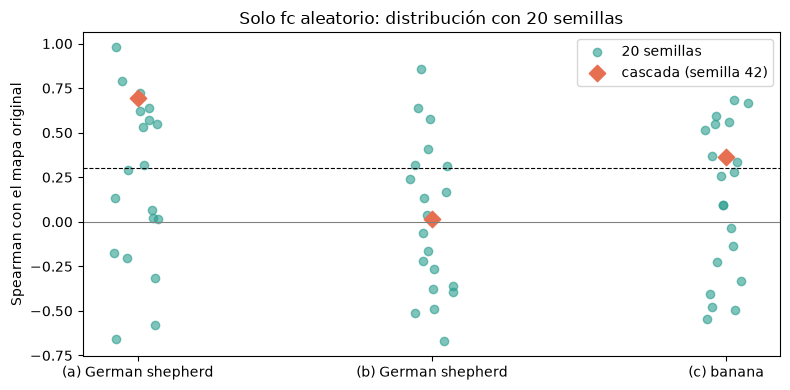

In [7]:
first_below = []
for key in loaded:
    column = cascade_table[key]
    below = column[column < 0.3]
    first_below.append({'imagen': key, 'primera_etapa_bajo_0.3': below.index[0] if len(below) else 'ninguna',
                        'spearman_en_esa_etapa': below.iloc[0] if len(below) else np.nan,
                        'spearman_maximo_posterior': column.loc[below.index[0]:].max() if len(below) else np.nan})
display(pd.DataFrame(first_below).style.format(precision=4).hide(axis='index'))

# Verificación de alpha = w / Z con fc aleatorio (imagen a).
torch.manual_seed(SEED)
fc_random = copy.deepcopy(model).eval()
fc_random.fc.reset_parameters()
check_cam = GradCAM(fc_random, fc_random.layer4)
check_cam(normalize(loaded['a']['rgb'][None]), loaded['a']['class_index'])
alpha = check_cam.gradients.mean(dim=(2, 3))[0].cpu()
activations_a = check_cam.activations[0].cpu()
check_cam.close()
w_over_z = fc_random.fc.weight[loaded['a']['class_index']].detach().cpu() / 49
print(f'fc aleatorio, imagen (a): máx |alpha - w/Z| = {(alpha - w_over_z).abs().max().item():.2e}')
print(f'Fracción de los 512 canales con activación media positiva: {(activations_a.mean(dim=(1, 2)) > 0).float().mean().item():.4f}')

# Estructura común de los canales: Spearman entre el promedio de los 512 mapas de activación y el mapa original.
structure_rows = []
for key, item in loaded.items():
    acts = {}
    hook = model.layer4.register_forward_hook(lambda module, inputs, output: acts.__setitem__('A', output.detach()))
    with torch.no_grad():
        model(normalize(item['rgb'][None]))
    hook.remove()
    channel_mean = acts['A'][0].mean(dim=0).cpu().numpy().ravel()
    structure_rows.append({'imagen': key, 'spearman_promedio_canales_vs_mapa_original':
                           spearmanr(channel_mean, item['raw_7'].numpy().ravel()).statistic})
display(pd.DataFrame(structure_rows).style.format(precision=4).hide(axis='index'))

# Solo fc aleatorio, 20 semillas.
FC_SEEDS = [1000 + s for s in range(20)]
fc_rows = []
for key, item in loaded.items():
    for seed in FC_SEEDS:
        torch.manual_seed(seed)
        net = copy.deepcopy(model).eval()
        net.fc.reset_parameters()
        cam = GradCAM(net, net.layer4)
        new_map = cam(normalize(item['rgb'][None]), item['class_index'])['normalized_7'].cpu()
        cam.close()
        fc_rows.append({'imagen': key, 'semilla': seed, 'spearman': spearman_or_nan(item['map_7'], new_map)})
fc_df = pd.DataFrame(fc_rows)
fc_df.to_csv(RESULTS_DIR / 'task4_3b_fc_seeds.csv', index=False)
fc_summary = fc_df.groupby('imagen')['spearman'].agg(
    media='mean', std='std', minimo='min', maximo='max',
    fraccion_sobre_0_3=lambda s: (s > 0.3).mean(), mapas_constantes=lambda s: s.isna().sum())
fc_summary['cascada_semilla_42'] = cascade_table.loc['fc']
display(fc_summary.style.format(precision=3))

fig, ax = plt.subplots(figsize=(8, 4))
for offset, key in enumerate(loaded):
    values = fc_df[fc_df['imagen'] == key]['spearman'].dropna()
    ax.scatter(np.full(len(values), offset) + np.random.default_rng(offset).uniform(-0.08, 0.08, len(values)),
               values, alpha=0.6, label='20 semillas' if offset == 0 else None, color='#2a9d8f')
    ax.scatter(offset, cascade_table.loc['fc', key], color='#e76f51', marker='D', s=70,
               label='cascada (semilla 42)' if offset == 0 else None)
ax.axhline(0.3, color='black', linewidth=0.8, linestyle='--')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xticks(range(3))
ax.set_xticklabels([f'({k}) {CLASS_NAMES[loaded[k]["class_index"]]}' for k in loaded])
ax.set_ylabel('Spearman con el mapa original')
ax.set_title('Solo fc aleatorio: distribución con 20 semillas')
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task4_3b_fc_seeds.png', dpi=180, bbox_inches='tight')
plt.show()

### Respuesta 4.3b

**Etapa en que el Spearman cae por debajo de 0.3.** En (b) ocurre ya en **`fc`** (0.017). En (a) y (c) ocurre en **`layer4`** (0.261 y −0.261). La caída no es definitiva: en etapas posteriores el Spearman vuelve a subir, hasta 0.480 en (a) con `layer3`, 0.327 en (b) con `layer2` y 0.425 en (c) con todo el modelo aleatorizado.

**Predicción para `fc`.** En este ResNet $\alpha_k^c=w_k^c/Z$. Al aleatorizar solo `fc`, las activaciones $A^k$ de `layer4` no cambian; solo cambian los pesos con que se combinan. Lo verificamos: con `fc` aleatorio, $\alpha_k$ coincide con $w_k/49$ con un error máximo de $1.75\times10^{-10}$. El mapa pasa a ser una combinación de los mismos 512 canales con pesos aleatorios de cualquier signo. Esos canales tienen una estructura espacial común: el 98.2% tiene activación media positiva, y el promedio de los 512 mapas de activación ya se parece al mapa original (Spearman 0.973 en (a), 0.735 en (c) y 0.235 en (b)). Por eso predecimos que el mapa pierde su relación con la clase, y que su Spearman con el original queda **centrado cerca de 0, pero con mucha dispersión y de cualquier signo**: según los pesos sorteados, la combinación se parece a la estructura común de los canales o a su inversa.

**Comparación con nuestro resultado.** Repetimos solo la etapa `fc` con 20 semillas:

| Imagen | Media | Desviación | Mínimo | Máximo | Fracción > 0.3 | Cascada (semilla 42) |
|---|---:|---:|---:|---:|---:|---:|
| (a) | 0.227 | 0.470 | −0.656 | 0.981 | 0.45 | 0.694 |
| (b) | 0.009 | 0.427 | −0.670 | 0.856 | 0.30 | 0.017 |
| (c) | 0.117 | 0.422 | −0.544 | 0.682 | 0.40 | 0.364 |

En (a), una de las 20 semillas produjo un mapa constante tras la ReLU, así que sus estadísticas usan 19 valores. Los valores de nuestra cascada caen dentro de esas distribuciones y la predicción se confirma: en promedio el mapa se descorrelaciona, sobre todo en (b), cuyo mapa original coincide poco con la estructura común de los canales. Pero una sola corrida puede dar un valor alto por azar, como el 0.694 de (a). Grad-CAM pasa la prueba de aleatorización en el sentido de que su mapa depende de los pesos del modelo, pero una cascada con una sola semilla no basta para concluirlo: hay que repetirla y mirar la distribución.

### 4.3c: Explicaciones para cada audiencia

Reunimos en una tabla las validaciones numéricas del Task 2 y del Task 3 en las que apoyamos la respuesta, leyéndolas de los archivos de resultados que esos notebooks guardaron.

In [8]:
import json

RESULTS_ROOT = PROJECT_ROOT / 'results'
task2 = json.loads((RESULTS_ROOT / 'task2' / 'summary.json').read_text(encoding='utf-8'))
stability = pd.read_csv(RESULTS_ROOT / 'task3' / 'task3_2_stability.csv')
lime31 = pd.read_csv(RESULTS_ROOT / 'task3' / 'task3_1_lime_three_clients.csv')
lime_shap = pd.read_csv(RESULTS_ROOT / 'task3' / 'task3_3a_lime_vs_shap.csv')
cf_metrics = pd.read_csv(RESULTS_ROOT / 'task3' / 'task3_4_metrics.csv')
counterfactuals = pd.read_csv(RESULTS_ROOT / 'task3' / 'task3_4_counterfactuals.csv')
importances = pd.read_csv(RESULTS_ROOT / 'task2' / 'task2_2c_importances.csv')
kernel = pd.DataFrame(task2['task_2_4'])

stab_075 = stability[stability['sigma_rel'] == 0.75].set_index('N')['jaccard_mean']
r2_values = lime31.groupby('cliente')['R2_w'].first()
spearman_col = [c for c in lime_shap.columns if c.startswith('spearman')][0]
age_row = importances.set_index('feature').loc['age']
cf1 = counterfactuals[counterfactuals['contrafactual'] == 1]

validation = pd.DataFrame([
    ('Desempeño del modelo', 'exactitud / AUC en prueba', f"{task2['task_2_1']['accuracy']:.3f} / {task2['task_2_1']['auc']:.3f}"),
    ('SHAP', 'error máximo de eficiencia (200 clientes)', f"{task2['task_2_2']['efficiency_max_abs_error']:.1e}"),
    ('SHAP', 'Shapley exacto frente a TreeSHAP', f"{task2['task_2_5']['max_abs_error_exact_vs_tree']:.1e}"),
    ('SHAP', 'MAE de KernelSHAP (fondos 10, 50, 100)', ', '.join(f'{v:.3f}' for v in kernel['mae_vs_matching_tree_shap'])),
    ('SHAP frente a permutación', 'Spearman entre rankings globales', f"{task2['task_2_2']['ranking_spearman']:.3f}"),
    ('Variable sensible', 'rango de age por SHAP / por permutación', f"{int(age_row['shap_rank'])} / {int(age_row['permutation_rank'])}"),
    ('LIME', 'Jaccard con N = 500 / 2000 / 5000 (σ_rel = 0.75)', ' / '.join(f'{stab_075[n]:.3f}' for n in [500, 2000, 5000])),
    ('LIME', 'R²_w con K = 5 (aprobado, rechazado, frontera)', ', '.join(f'{r2_values[c]:.3f}' for c in ['aprobado', 'rechazado', 'frontera'])),
    ('LIME frente a SHAP', 'Spearman por cliente', ', '.join(f'{v:.3f}' for v in lime_shap[spearman_col])),
    ('Contrafactuales', 'validez (fracción de candidatos válidos)', f"{cf_metrics['validez'].iloc[0]:.3%}"),
    ('Contrafactuales', 'contrafactual 1 del rechazado',
     '; '.join(f"{r.variable}: {r.valor_original} → {r.valor_nuevo}" for r in cf1.itertuples()) + f" (p = {cf1['p_good'].iloc[0]:.3f})"),
], columns=['tecnica', 'validacion', 'resultado'])
validation.to_csv(RESULTS_DIR / 'task4_3c_validations.csv', index=False)
display(validation.style.hide(axis='index'))

tecnica,validacion,resultado
Desempeño del modelo,exactitud / AUC en prueba,0.775 / 0.765
SHAP,error máximo de eficiencia (200 clientes),9.7e-08
SHAP,Shapley exacto frente a TreeSHAP,2.1e-08
SHAP,"MAE de KernelSHAP (fondos 10, 50, 100)","0.045, 0.040, 0.041"
SHAP frente a permutación,Spearman entre rankings globales,0.645
Variable sensible,rango de age por SHAP / por permutación,6 / 20
LIME,Jaccard con N = 500 / 2000 / 5000 (σ_rel = 0.75),0.816 / 0.937 / 1.000
LIME,"R²_w con K = 5 (aprobado, rechazado, frontera)","0.242, 0.300, 0.279"
LIME frente a SHAP,Spearman por cliente,"0.737, 0.952, 0.869"
Contrafactuales,validez (fracción de candidatos válidos),0.855%


### Respuesta 4.3c

**Persona solicitante.** Le entregaríamos las tres razones principales de su decisión según SHAP, en lenguaje claro y con su dirección. Para el cliente rechazado: el historial `all paid` fue lo que más pesó en contra ($\phi=-1.32$), luego el monto solicitado ($-0.96$), y sus ahorros de al menos 1000 fueron lo que más lo favoreció ($+0.97$). Lo respaldamos con la eficiencia de SHAP (error máximo $9.7\times10^{-8}$ en los 200 clientes de prueba): las razones suman exactamente la decisión del modelo. **No le entregaríamos** los coeficientes de LIME, porque solo explican entre el 24% y el 30% del comportamiento del modelo ($R^2_w$ de 0.242 a 0.300), ni el contrafactual automático del Task 3.4: "pida 392 en vez de 433" aprovecha un valle del modelo entre 431 y 451 que no tiene sentido económico. Tampoco presentaríamos variables inmutables como la edad como algo que la persona deba cambiar.

**Oficial de cumplimiento interno.** Le entregaríamos las cascadas de SHAP por caso y la importancia global, y LIME como segunda opinión, siempre con su estabilidad (Jaccard 1.000 con $N=5000$, pero 0.816 con $N=500$), su fidelidad ($R^2_w$ de 0.242 a 0.300) y su acuerdo con SHAP (Spearman de 0.737 a 0.952). También le reportaríamos los riesgos del modelo que encontramos: el valle de `credit_amount` creado por dos clientes de entrenamiento, el cliente aprobado con $p=0.9994$ que en realidad es bad, la codificación ordinal arbitraria de las categóricas y el peso de variables sensibles, como `age` (sexta por $|\phi|$). **No le entregaríamos** LIME sin su $R^2_w$ ni resultados de una sola semilla presentados como definitivos.

**Regulador.** Le entregaríamos la documentación del modelo y de la validación de sus explicaciones: desempeño (exactitud 0.775, AUC 0.765); importancia global por SHAP y por permutación con su discrepancia (Spearman 0.645; `age` sexta por SHAP y vigésima por permutación); las verificaciones numéricas (eficiencia, Shapley exacto frente a TreeSHAP con error $2.1\times10^{-8}$, KernelSHAP con error medio de 0.040 a 0.045); las tablas de estabilidad y fidelidad de LIME; la validez de los contrafactuales (0.855%); y las limitaciones, como la codificación ordinal y el reparto del crédito entre variables redundantes del Task 2.3. **No le entregaríamos** datos individuales de clientes, por privacidad, ni explicaciones sin su validación.

**Contrafactuales en detección de lavado.** En un sistema como el del Proyecto 2, que marca secuencias de transacciones sospechosas, un contrafactual le diría a la persona investigada exactamente qué modificar para dejar de ser detectada: partir montos, cambiar el ritmo de las transferencias o evitar ciertos destinos. En nuestro modelo de crédito vimos que un cambio de apenas 41 unidades en el monto basta para cambiar la decisión; en lavado, eso equivale a enseñar a evadir el sistema. Además, la regulación contra el lavado prohíbe avisar a la persona de que está siendo reportada (*tipping off*). En lugar de contrafactuales entregaríamos explicaciones solo internas para los analistas: qué transacciones de la secuencia pesaron más en la alerta (los pesos de atención o SHAP por transacción), contrastadas con las etiquetas por transacción, y reportes agregados para auditoría, nunca guías de cambio dirigidas al cliente.